In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
from sklearn.decomposition import PCA

# Linear Algebra for AI

This notebook covers the key linear algebra concepts that underpin modern AI and ML systems. Each section starts with *why it matters*, builds the concept from scratch, and finishes with hands-on tasks.


# 1. Vectors and vector operations

## Why this matters

Before any ML model sees your data, it must be turned into numbers. A vector is simply an ordered list of numbers - the format in which almost all data enters a model.

- A customer profile might be represented as `[age, income, purchase_frequency]`
- A word in an NLP model might be a 300-dimensional vector (a word embedding)
- An image patch might be thousands of pixel values flattened into one vector

Understanding what vectors *are*, and how we measure similarity between them, is foundational to understanding recommendation systems, search, neural networks, and more.

## Vector representation

In [4]:
# A 2D vector (e.g., a data point with 2 features)

v1 = np.array([3, 4])
print(v1)
print(v1.shape)

[3 4]
(2,)


In [5]:
# A 3D vector (e.g., a data point with 3 features)

v2 = np.array([100, 150, 200])

print(v2)
print(v2.shape)

[100 150 200]
(3,)


Representation of vectors in 3D space: https://www.math3d.org/h5rJIngJVD


In [6]:
# A higher-dimensional vector (e.g., a word embedding of 50 dimensions(words))

v3 = np.random.rand(50) # Generates 50 random numbers between 0 and 1

print(v3)
print(v3.shape)

[0.81617124 0.67362443 0.13496814 0.53916565 0.23027296 0.96621779
 0.22293384 0.62951609 0.96835729 0.69830151 0.3083376  0.38103276
 0.42263808 0.28651485 0.08627684 0.69979319 0.65822063 0.08355374
 0.00190731 0.82604282 0.96101537 0.79674834 0.68827083 0.33290903
 0.82012808 0.2502282  0.53262188 0.54890224 0.12714423 0.91551732
 0.70206983 0.64274659 0.64028726 0.5357965  0.90288239 0.31516045
 0.79790312 0.04385596 0.7786099  0.73073975 0.23843198 0.83375898
 0.44743338 0.15270192 0.57450906 0.07988751 0.30602548 0.00334023
 0.98021876 0.60157309]
(50,)


## Visualising vectors in 2D

For 2D and 3D vectors, we can visualise them as arrows from the origin. This geometric intuition is useful: the *direction* of the arrow represents what the vector is "pointing at", and the *length* represents its magnitude.

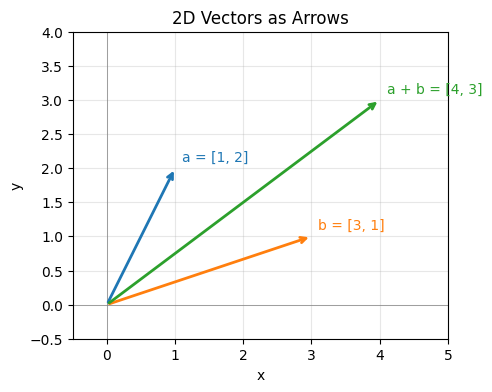

In [7]:
# Visualise 2D vectors as arrows
fig, ax = plt.subplots(figsize=(5, 5))

vectors = {
    'a = [1, 2]': ([1, 2], 'tab:blue'),
    'b = [3, 1]': ([3, 1], 'tab:orange'),
    'a + b = [4, 3]': ([4, 3], 'tab:green'),
}

for label, (vec, colour) in vectors.items():
    ax.annotate('', xy=(vec[0], vec[1]), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color=colour, lw=2))
    ax.text(vec[0] + 0.1, vec[1] + 0.1, label, color=colour, fontsize=10)

ax.set_xlim(-0.5, 5)
ax.set_ylim(-0.5, 4)
ax.axhline(0, color='grey', linewidth=0.5)
ax.axvline(0, color='grey', linewidth=0.5)
ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title('2D Vectors as Arrows')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Vector operations

In [8]:
# Let's define 2D vectors
a = np.array([1, 2])
b = np.array([3, 1])

print(a)
print(b)

[1 2]
[3 1]


### Addition/Subtraction

In [9]:
# Vector Addition (a + b)
# Mathematically: (1+3, 2+1) = (4,3)

vec_sum = a + b

print(vec_sum)

[4 3]


In [10]:
# Vector Subtraction (a - b)
# Mathematically: (1-3, 2-1) = (-2,1)

vec_diff = a - b
print(vec_diff)

[-2  1]


### Scalar multiplication

In [11]:
# Scalar Multiplication (2 * a)
# Mathematically: (2*1, 2*2) = (2,4)

scalar_mult = 2 * a
print(scalar_mult)

[2 4]


### Dot product

The dot product is a fundamental operation. It takes two vectors and returns a single scalar value.

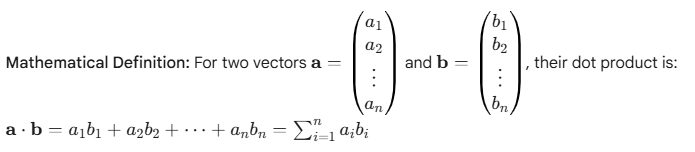

The **dot product** is related to **the angle** between the two vectors and **their magnitudes**. 
Specifically, **a⋅b=∣∣a∣∣⋅∣∣b∣∣⋅cos(θ)**, where **θ is the angle between them**.

- If vectors are in the same direction (θ=0), cos(θ)=1, **dot product is maximum (positive)**.
- If vectors are orthogonal (perpendicular, θ=90), cos(θ)=0, **dot product is 0**.
- If vectors are in opposite directions (θ=180), cos(θ)=−1, **dot product is maximum (negative)**.

#### ML relevance: 

- **Similarity measures**: Cosine similarity - e.g., word embeddings, docuemnt vectors). If the doct product is high, the vectors are similar in direction.

- **Neuron activation**: In neural networks, the input features are multiplied by weights (both vectors) using a dot product, forming the weighted sum that feeds into the activation function.

- **Projections**: Used to project one vector onto another.

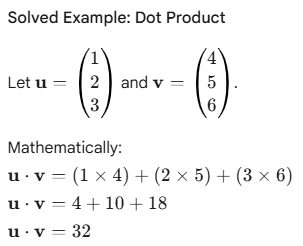

### Visualising the dot product geometrically

The dot product tells you *how much two vectors point in the same direction*. Run the cell below to see this for three vector pairs.

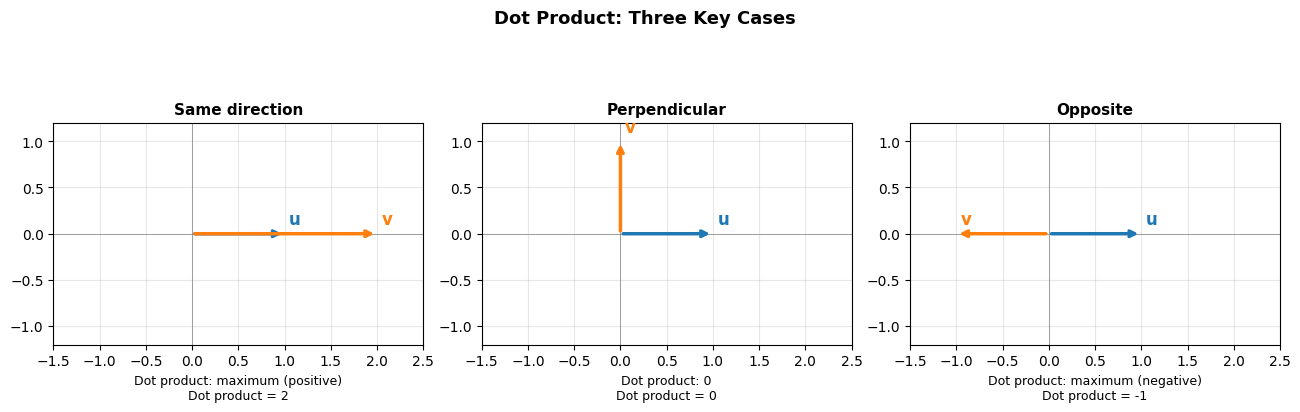

In [12]:
# Visualise dot product geometry
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

pairs = [
    ('Same direction', [1, 0], [2, 0], 'Dot product: maximum (positive)'),
    ('Perpendicular',  [1, 0], [0, 1], 'Dot product: 0'),
    ('Opposite',       [1, 0], [-1, 0], 'Dot product: maximum (negative)'),
]

for ax, (title, u, v, note) in zip(axes, pairs):
    dp = np.dot(u, v)
    for vec, col, lbl in [(u, 'tab:blue', 'u'), (v, 'tab:orange', 'v')]:
        ax.annotate('', xy=(vec[0], vec[1]), xytext=(0, 0),
                    arrowprops=dict(arrowstyle='->', color=col, lw=2.5))
        ax.text(vec[0]+0.05, vec[1]+0.1, lbl, color=col, fontsize=12, fontweight='bold')
    ax.set_xlim(-1.5, 2.5); ax.set_ylim(-1.2, 1.2)
    ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(f'{note}\nDot product = {dp}', fontsize=9)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)

plt.suptitle('Dot Product: Three Key Cases', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [13]:
# NumPy implementation
u = np.array([1, 2, 3])
v = np.array([4, 5, 6])

dot_product = np.dot(u, v)

# or use the @ operator - matrix multiplication operator
dot_product_at = u @ v

print(u)
print(v)
print(dot_product)
print(dot_product_at)

[1 2 3]
[4 5 6]
32
32


### Task 1.1: Dot product for feature vectors

Imagine three simple "customer profile" vectors where each element represents a feature (e.g., [Age, Income_k, Purchase_Freq]).

- customer1 = np.array([30, 50, 10])
- customer2 = np.array([35, 60, 12])
- customer3 = np.array([28, 45, 2])
  
Calculate the dot product between:
1. customer1 and customer2
2. customer1 and customer3
   
Which pair of customers appears more "aligned" in terms of their overall profiles based on the dot product value?

In [14]:
# your code here
customer1 = np.array([30,50,10])
customer2 = np.array([35,60,12])
customer3 = np.array([28,45,2])

dot1and2 = customer1 @ customer2
dot1and3 = customer1 @ customer3

print("Dot product of customer1 and customer2:", dot1and2)
print("Dot product of customer1 and customer3:", dot1and3)

if dot1and2 > dot1and3:
    print("Customer 1 and Customer 2 are more similar.")
else:
    print("Customer 1 and Customer 3 are more similar.")

#Customer 1 and 2 are more similar.

Dot product of customer1 and customer2: 4170
Dot product of customer1 and customer3: 3110
Customer 1 and Customer 2 are more similar.


### Task 1.2: Cosine similarity

Using the formula for cosine similarity

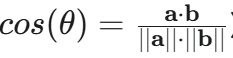

calculate the cosine similarity between customer1 and customer3.

Remember that

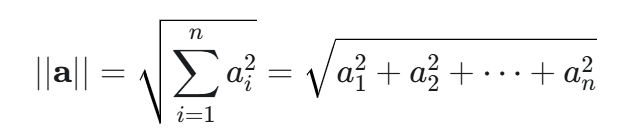

This represents the "length" of the vector in a multi-dimensional space, derived from the Pythagorean theorem.

For example: let **a** be the vector customer1 from our task:

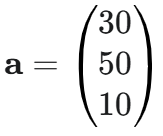

We want to calculate its magnitude ∣∣a∣∣.

Step-by-step calculation:

1. Square each element:

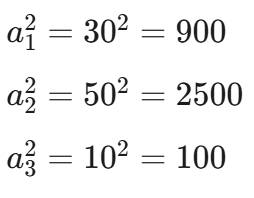

2. Sum the squared elements:

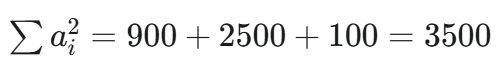

3. Take the square root of the sum:

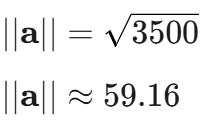

You can use np.linalg.norm() for the vector magnitude. (The np.linalg.norm() function computes the Euclidean norm (magnitude) of a vector.)

In [15]:
# How to compute the vector magnitude with NumPy

customer1 = np.array([30, 50, 10])
norm_customer1 = np.linalg.norm(customer1)

print(norm_customer1)

59.16079783099616


#### Pause and reflect

- Cosine similarity returns a value between -1 and 1. What would a score of 0 mean in the context of customer profiles? What about a score of 1?
    - A score of 0 would suggest no relation at all. A score of 1 would show strong relation between the customers. 
- In NLP, words like "king" and "queen" tend to have high cosine similarity. Can you think of why a raw dot product score wouldn't be as useful as cosine similarity for comparing word embeddings of very different magnitudes?
    - Raw dot compares direction AND magnitude, which can distort similarities as high values can give higher scores even when they are not similar 
    -  cosine similarity focuses on direction (removing magnitude) which is better for measuring similarity between words

# 2. Matrices and matrix operations

## Why this matters

If a vector is a single data point, a **matrix** is a whole dataset - or a transformation. In ML:

- Your training data **X** is a matrix: each row is one sample, each column is one feature
- The weights of a neural network layer are stored in a matrix
- Transformations like PCA, rotations, and projections are all matrix operations

Almost every forward pass in a neural network is a sequence of matrix multiplications.

## Matrix representation

In [16]:
# A 2x3 matrix (2 rows, 3 columns)
# Example: A dataset with 2 samples and 3 features

data_matrix = np.array([[10, 20, 30],
                        [40, 50, 60]])

print(data_matrix)
print(data_matrix.shape)

[[10 20 30]
 [40 50 60]]
(2, 3)


In [17]:
# Another matrix (e.g., weights in a small neural network layer)

weights_matrix = np.array([[0.1, 0.2],
                           [0.3, 0.4],
                           [0.5, 0.6]])

print(weights_matrix)
print(weights_matrix.shape)

[[0.1 0.2]
 [0.3 0.4]
 [0.5 0.6]]
(3, 2)


### Visualising a matrix as a dataset

A dataset matrix X (rows = samples, columns = features) can be plotted as a scatter chart. This makes the abstract array of numbers feel concrete.

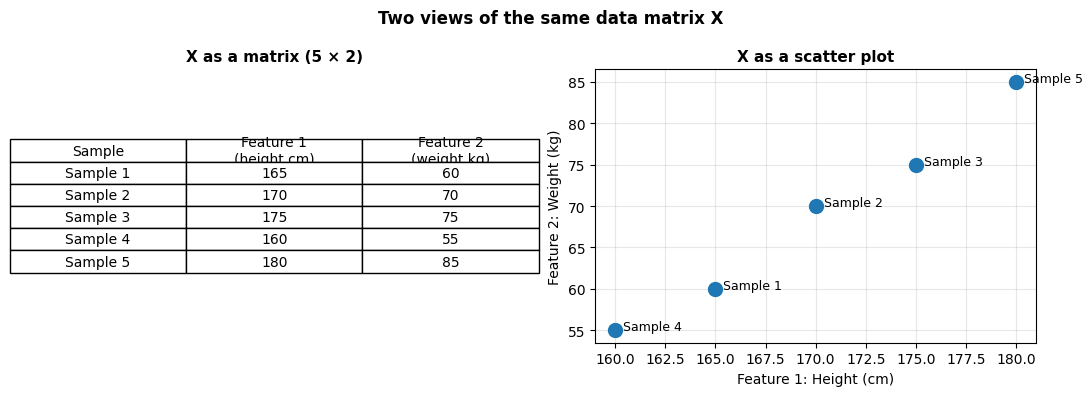

In [18]:
# Visualise a small dataset matrix as a scatter plot
# Matrix: 5 samples, 2 features [height_cm, weight_kg]
X = np.array([
    [165, 60],
    [170, 70],
    [175, 75],
    [160, 55],
    [180, 85],
])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Left: show the matrix as a table
axes[0].axis('off')
table_data = [['Sample', 'Feature 1\n(height cm)', 'Feature 2\n(weight kg)']]
for i, row in enumerate(X):
    table_data.append([f'Sample {i+1}', str(row[0]), str(row[1])])
table = axes[0].table(cellText=table_data[1:], colLabels=table_data[0],
                       loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.5)
axes[0].set_title('X as a matrix (5 × 2)', fontsize=11, fontweight='bold')

# Right: scatter plot
axes[1].scatter(X[:, 0], X[:, 1], color='tab:blue', s=100, zorder=3)
for i, (h, w) in enumerate(X):
    axes[1].annotate(f'  Sample {i+1}', (h, w), fontsize=9)
axes[1].set_xlabel('Feature 1: Height (cm)')
axes[1].set_ylabel('Feature 2: Weight (kg)')
axes[1].set_title('X as a scatter plot', fontsize=11, fontweight='bold')
axes[1].grid(True, alpha=0.3)

plt.suptitle('Two views of the same data matrix X', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Basic matrix operations

Like vectors, matrices support:
- element-wise operations: **addition, subtraction, scalar multiplication**
- non-element-wise operation: **multiplication**

**Matrix transpose**:
The transpose of a matrix (denoted $A^T$
 ) is obtained by flipping the matrix over its diagonal, effectively swapping row and column indices. Rows become columns, and columns become rows.

If $A$ is (m x n), then $A^T$ is (n x m).

In [19]:
print(data_matrix)

[[10 20 30]
 [40 50 60]]


In [20]:
data_matrix_T = data_matrix.T
print(data_matrix_T)

[[10 40]
 [20 50]
 [30 60]]


### Matrix addition and scalar multiplication

(Requires matrices to have the same dimensions for addition/subtraction.)

In [21]:
m1 = np.array([[1, 2], [3, 4]])
m2 = np.array([[5, 6], [7, 8]])

print(m1)
print(m2)

[[1 2]
 [3 4]]
[[5 6]
 [7 8]]


In [22]:
# Matrix Addition

matrix_sum = m1 + m2
print(matrix_sum)

[[ 6  8]
 [10 12]]


In [23]:
# Scalar Multiplication

scalar_matrix = 3 * m1

print(scalar_matrix)

[[ 3  6]
 [ 9 12]]


### Matrix multiplication

Matrix multiplication is not element-wise.

**Rule for multiplication (A×B)**: The number of columns in the first matrix (A) must equal the number of rows in the second matrix (B).

- If A is an (m×**n**) matrix and B is an (**n**×p) matrix, then the resulting product C will be an **(m×p)** matrix.
- The "neighboring dimensions" **(n and n)** must match. The "outer dimensions" (m and p) define the shape of the result.

#### ML relevance

- **Neural Networks**: The core computation in a neural network layer is a matrix multiplication: output = input_data @ weights_matrix + bias_vector.
- **Transformations**: Projecting data into a new space (e.g., feature engineering, PCA).
- **Linear Models**: At the heart of many linear models.

**Example 1**:

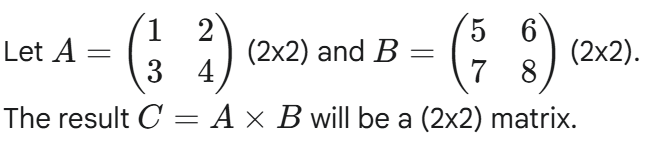

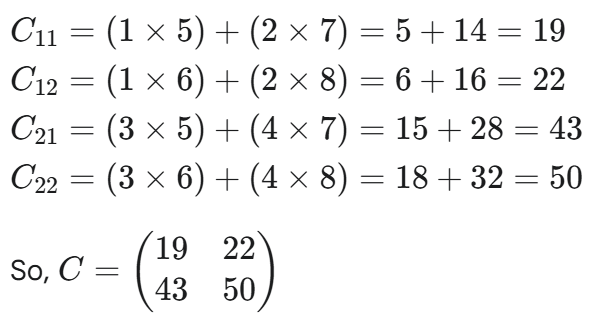

**Example 2:** 


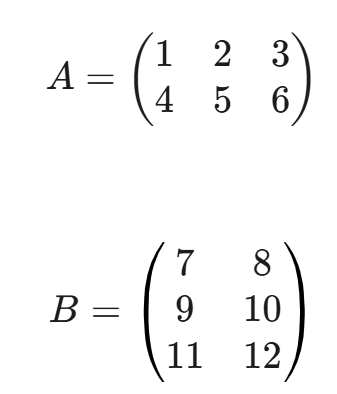

We want to calculate the product C=A×B.
Since A is (2x3) and B is (3x2), the resulting matrix C will have dimensions (2x2).

Each element in the resulting matrix C is calculated by taking the dot product of a row from the first matrix (A) and a column from the second matrix (B).

For C11 we calculate the dot product of **row 1 of A and and column 1 of B**

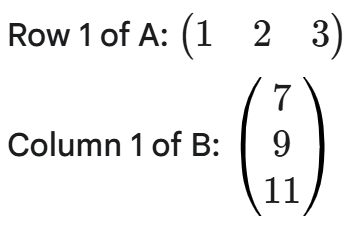

In [24]:
# Write the calculations for C11 here. Verify the output using the Numpy calculations below.
c11 = (1*7) + (2*9) + (3*11)
print(c11)
# Answer = 58

58


In [25]:

A = np.array([[1,2,3],[4,5,6]])
B = np.array([[7,8],[9,10],[11,12]])

C = np.dot(A, B)
print(C)


[[ 58  64]
 [139 154]]


In [26]:
# Define matrix a (2x3)
A = np.array([[1, 2, 3],
             [4, 5, 6]])

# Define matrix b (3x2)
B = np.array([[7, 8],
              [9, 10],
              [11, 12]])

print(A)
print()
print(B)

[[1 2 3]
 [4 5 6]]

[[ 7  8]
 [ 9 10]
 [11 12]]


In [27]:
# Matrix multiplication A@B

C = A @ B
print(C)

[[ 58  64]
 [139 154]]


**What if we try B @ A?**

In [28]:
# try here
# what did you notice?

print(B@A)

[[ 39  54  69]
 [ 49  68  87]
 [ 59  82 105]]


**Important**: Matrix multiplication is generally NOT commutative (A @ B != B @ A)

### Visualising matrix multiplication as a transformation

Multiplying a set of data points by a transformation matrix *moves* them to a new location in space. Run the cell below to see how a 2×2 matrix transforms a grid of points — this is the geometric intuition behind feature engineering, PCA, and neural network layers.

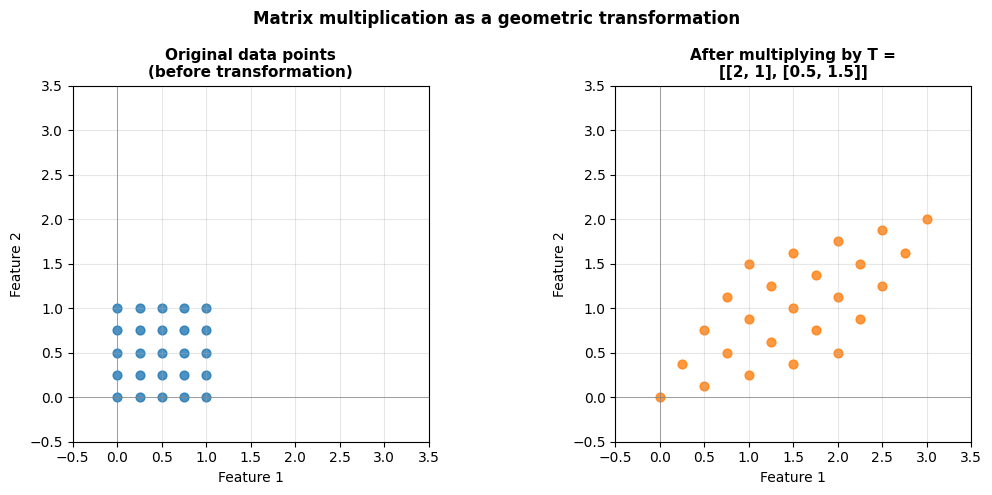

Notice: the shape of the data has been stretched and sheared.
This is exactly what happens to your data in each layer of a neural network.


In [29]:
# Visualise what matrix multiplication does geometrically
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# Create a grid of points (a square shape)
grid_points = []
for x in np.linspace(0, 1, 5):
    for y in np.linspace(0, 1, 5):
        grid_points.append([x, y])
grid_points = np.array(grid_points)

# Transformation matrix: scales and shears
T = np.array([[2, 1],
              [0.5, 1.5]])

transformed = grid_points @ T.T

# Plot original
axes[0].scatter(grid_points[:, 0], grid_points[:, 1], color='tab:blue', s=40, alpha=0.8)
axes[0].set_title('Original data points\n(before transformation)', fontsize=11, fontweight='bold')
axes[0].set_xlim(-0.5, 3.5); axes[0].set_ylim(-0.5, 3.5)
axes[0].set_xlabel('Feature 1'); axes[0].set_ylabel('Feature 2')
axes[0].set_aspect('equal'); axes[0].grid(True, alpha=0.3)
axes[0].axhline(0, color='grey', lw=0.5); axes[0].axvline(0, color='grey', lw=0.5)

# Plot transformed
axes[1].scatter(transformed[:, 0], transformed[:, 1], color='tab:orange', s=40, alpha=0.8)
axes[1].set_title(f'After multiplying by T =\n[[2, 1], [0.5, 1.5]]', fontsize=11, fontweight='bold')
axes[1].set_xlim(-0.5, 3.5); axes[1].set_ylim(-0.5, 3.5)
axes[1].set_xlabel('Feature 1'); axes[1].set_ylabel('Feature 2')
axes[1].set_aspect('equal'); axes[1].grid(True, alpha=0.3)
axes[1].axhline(0, color='grey', lw=0.5); axes[1].axvline(0, color='grey', lw=0.5)

plt.suptitle('Matrix multiplication as a geometric transformation', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("Notice: the shape of the data has been stretched and sheared.")
print("This is exactly what happens to your data in each layer of a neural network.")

### Task 2.1: Dataset transformation

Imagine a small dataset ***X_data*** (3 samples, 2 features) and a ***transformation_matrix*** (2x2) that scales and rotates the features. 

Perform the transformation: X_transformed = X_data @ transformation_matrix. 

What are the dimensions of the transformed data?

In [30]:
# Create the X_data and transformation matrix
# your code here
X_data = np.array([[0, 0],
                   [1, 0],
                   [0, 1]]
                   )

transformation_matrix = np.array([[2, 1],
                                  [0.5, 1.5]])



# Perform the transformation
# your code here
transformed_data = X_data @ transformation_matrix
print("Transformed data:\n", transformed_data)

Transformed data:
 [[0.  0. ]
 [2.  1. ]
 [0.5 1.5]]


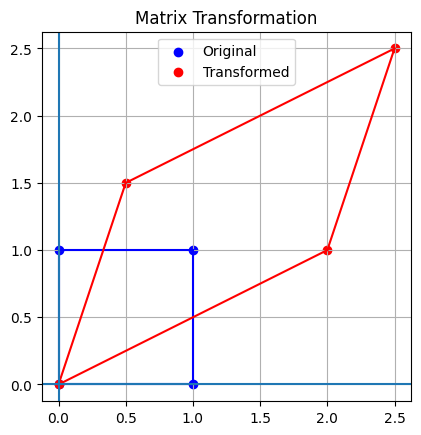

In [31]:

# Original points
X_data = np.array([
    [0, 0],
    [1, 0],
    [0, 1],
    [1, 1]
])

# Transformation matrix
transformation_matrix = np.array([
    [2, 1],
    [0.5, 1.5]
])

# Transform
transformed_data = X_data @ transformation_matrix

# Plot
plt.scatter(X_data[:,0], X_data[:,1], label="Original", color="blue")
plt.scatter(transformed_data[:,0], transformed_data[:,1], label="Transformed", color="red")

# Draw lines (to show shape)
for data, color in [(X_data, "blue"), (transformed_data, "red")]:
    plt.plot([data[0,0], data[1,0]], [data[0,1], data[1,1]], color=color)
    plt.plot([data[0,0], data[2,0]], [data[0,1], data[2,1]], color=color)
    plt.plot([data[1,0], data[3,0]], [data[1,1], data[3,1]], color=color)
    plt.plot([data[2,0], data[3,0]], [data[2,1], data[3,1]], color=color)

plt.axhline(0)
plt.axvline(0)
plt.gca().set_aspect('equal', adjustable='box')

plt.legend()
plt.title("Matrix Transformation")
plt.grid(True)
plt.show()


### OTJ Task 2.2: Simple neural network layer

Consider an input layer ***input_features*** with 1 sample and 3 features. 

This is multiplied by a ***weights_layer1*** matrix (3 features -> 2 neurons in the next layer), and a ***bias_layer1*** vector.

***output_layer1 = input_features @ weights_layer1 + bias_layer1***

Calculate ***output_layer1.***

Example: 

Input features (1 sample, 3 features)

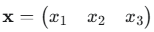

Weights for Layer 1 (3 inputs to 2 neurons):

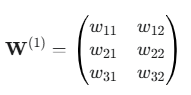

Here, $w_{ij}$
is the weight connecting input i to neuron j in the next layer.

Bias for Layer 1 (for 2 neurons):

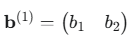

The weighted sum for the entire layer is obtained by matrix multiplication of the input vector by the weight matrix, then adding the baias vector. The general formula is:

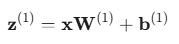

So, for each neuron in the layer:

For Neuron 1 in Layer 1:

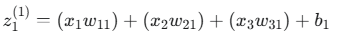

For Neuron 2 in Layer 1:

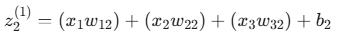

The final output is:

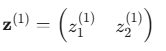

In [32]:
# Create these matrices in NumPy (think of some numbers for the input features vector, the weights and bias values.
# Then calculate output_layer1 = input_features @ weights_layer1 + bias_layer1
input_features = np.array([1.0, 2.0, 3.0])  # Example input features (3 features)
print("Input features:", input_features)
weights_layer1 = np.array([[0.2, 0.4],   # Weights for layer 1 (3 features to 2 neurons)
                           [0.5, 0.1],
                           [0.3, 0.6]])
print("Weights for layer 1:\n", weights_layer1)
bias_layer1 = np.array([0.1, 0.2])  # Bias for layer 1 (2 neurons)  
print("Bias for layer 1:", bias_layer1)

# your code here
output_layer1 = input_features @ weights_layer1 + bias_layer1
print("Output of layer 1:", output_layer1)

Input features: [1. 2. 3.]
Weights for layer 1:
 [[0.2 0.4]
 [0.5 0.1]
 [0.3 0.6]]
Bias for layer 1: [0.1 0.2]
Output of layer 1: [2.2 2.6]


# 3. Systems of linear equations and the pseudoinverse

## Why this matters

Training a linear regression model is, at its core, solving a system of linear equations. You have many data points (equations) and you want to find model parameters (unknowns) that fit them as closely as possible.

When the system is *overdetermined* (more data points than parameters, which is almost always), there's no exact solution. The **pseudoinverse** gives you the best possible approximate solution - the one that minimises the total prediction error. This is the analytical foundation of **Ordinary Least Squares regression**.

Many problems in ML boil down to finding a set of unknown values (e.g., model parameters, coefficients) that satisfy a set of linear equations. This can be expressed in matrix form as **Ax=b**.

- **A**: The coefficient matrix (often your input features, or a transformation matrix).
- **x**: The vector of unknowns (e.g., the weights/parameters you want to find for your model).
- **b**: The result vector (e.g., your target labels or observations).

Consider the system:

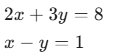

This can be written in matrix form as **Ax=b**:

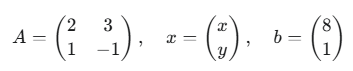

We want to find the values of **x** and **y**.

## Square systems

When A is a square matrix (number of equations equals number of unknowns) and is invertible, we can find a unique exact solution for x.

If A is invertible, then $x=A^{-1}b$


**A square matrix A is said to be invertible** (or non-singular) if there exists another square matrix, denoted $A^{−1}$
  (read as "A inverse"), of the same dimensions, such that when A is multiplied by $A^{−1}$
  (in either order), the result is the **Identity Matrix (I)**.

***$AA^{−1}$ = I*** and  ***$A^{−1}A$ = I***

The Identity Matrix (I) is a square matrix with ones on the main diagonal and zeros elsewhere. For example a 2x2 matrix:

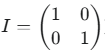

It acts like the number '1' in scalar multiplication (a⋅1=a).

How to check if a matrix is invertible:

For a square matrix A, it is invertible if and only if its determinant is non-zero (det(A)≠0).

If det(A)=0, the matrix is singular (not invertible). This means its columns (or rows) are linearly dependent, and it maps multiple distinct vectors to the same output, or collapses dimensions, making it impossible to uniquely "undo" the transformation.

For a general 2x2 matrix

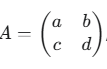

its inverse $A^{−1}$ can be calculated using the following formula:

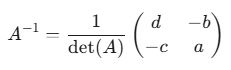

where **det(A)=ad−bc**.

**Important note**: For matrices larger than 2x2, the manual calculation of the inverse becomes much more complex (involving cofactors, adjugate matrices, or Gauss-Jordan elimination). In practice, you would always use numerical libraries like NumPy for this.

Let's solve an example. Consider the system:

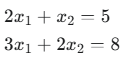

In matrix form, Ax=b:

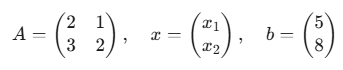

In [33]:
# Define A and b
A = np.array([[2, 1],
              [3, 2]])

b = np.array([5, 8])

print(A)
print(b)

[[2 1]
 [3 2]]
[5 8]


In [34]:
# Check if A is invertible

det_A = np.linalg.det(A)

print(det_A)

0.9999999999999998


In [35]:
if det_A != 0:
    x_solution = np.linalg.solve(A, b)
    print(x_solution)
else:
    print("Matrix A is singular (not invertible). Cannot find unique exact solution.")

[2. 1.]


## Overdetermined systems and the pseudoinverse

In Machine Learning, you often have more data points (equations) than features/parameters (unknowns). 

This creates an overdetermined system, where an exact solution (Ax=b) usually doesn't exist because the lines or planes defined by the equations may not intersect at a single point due to noise in real-world data.

Ordinary Least Squares(OLS) Regression:
https://phet.colorado.edu/sims/html/least-squares-regression/latest/least-squares-regression_en.html


Instead, we seek **the "best fit" approximate solution** that minimises the error. This is where the **pseudoinverse** comes in.

For an overdetermined system **Ax ≈ b**, the solution **x** that minimises the squared error **$∣∣Ax−b∣∣^2$** is given by:

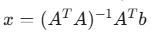

This is known as the **Normal Equation** for Ordinary Least Squares (OLS). The term $(A^TA)^{-1}A^T$ is the pseudoinverse of $A$, often denoted $A^+$. NumPy provides ***np.linalg.pinv()*** for this.

#### ML relevance:
- Linear Regression: This formula provides the analytical (closed-form) solution for the coefficients (weights) in Linear Regression. You're finding the line (or hyperplane) that best fits your data by minimising the sum of squared residuals.

Here is a solved example. 

Let's find the **slope (m)** and **intercept (c)** for a simple linear regression model **y=mx+c** that best fits three data points: **(1,2),(2,3),(3,4.5)**.

We can set this up as an overdetermined system:

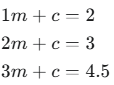

In matrix form, Ax=b:

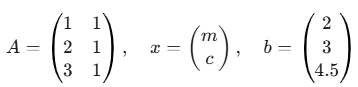

The solution $\hat{x}$ (the optimal m and c) for the linear regression model that minimises the squared errors is given by the Normal Equation:

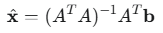

Let's calculate each part step-by-step.
1. Calculate $A^T$(Transpose of A)

To get $A^T$, we swap the rows and columns of A:

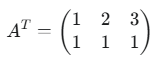

2. Calculate $A^TA$

Now, multiply $A^T$(2x3) by A (3x2). The result will be a (2x2) matrix.

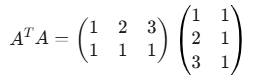

- Element (1,1): (1×1)+(2×2)+(3×3)=1+4+9=14
- Element (1,2): (1×1)+(2×1)+(3×1)=1+2+3=6
- Element (2,1): (1×1)+(1×2)+(1×3)=1+2+3=6
- Element (2,2): (1×1)+(1×1)+(1×1)=1+1+1=3

So, 

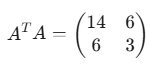

3. Calculate $(A^TA)^{-1}$ (Inverse of $A^TA$)

Let 

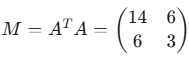

First, we calculate the determinant of M:

det(M)=(14×3)−(6×6)=42−36=6

Since det(M) = 6 ≠ 0, the matrix is invertible.

Now, use the 2x2 inverse formula:

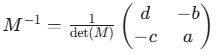

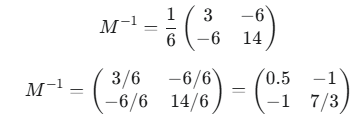

4. Calculate $A^T$b

Now, multiply **$A^T$** (2x3) by **b** (3x1 vector). The result will be a (2x1) vector.

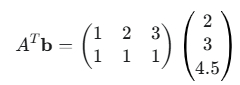

- Element (1): (1×2)+(2×3)+(3×4.5)=2+6+13.5=21.5
- Element (2): (1×2)+(1×3)+(1×4.5)=2+3+4.5=9.5

5. Calculate  $\hat{x}$ = $(A^TA)^{-1}A^T$b

Finally, multiply the inverse matrix from Step 3 by the vector from Step 4.

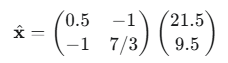

- Element (1) - for **m**: (0.5×21.5)+(−1×9.5)=10.75−9.5=**1.25**
- Element (2) - for **c**: (−1×21.5)+(7/3×9.5)=−21.5+(66.5/3)=−21.5+22.166...=**0.666**...

Thus, the best-fit linear regression line is: **y=1.25x+0.667**

In [36]:
# Create A and b
A = np.array([[1, 1],
              [2, 1],
              [3, 1]])
b = np.array([2, 3, 4.5])
print(A)
print(b)

[[1 1]
 [2 1]
 [3 1]]
[2.  3.  4.5]


In [37]:
# Calculate the pseudoinverse solution x = (A^T A)^-1 A^T * b
# This finds the 'm' and 'c' that best fit the data

coefficients = np.linalg.pinv(A) @ b

print(coefficients)

[1.25       0.66666667]


In [38]:
# What does this mean? 
# For y = mx + c, 
m = coefficients[0], 
c = coefficients[1]
print(m)
print(c)


(np.float64(1.2499999999999991),)
0.6666666666666681


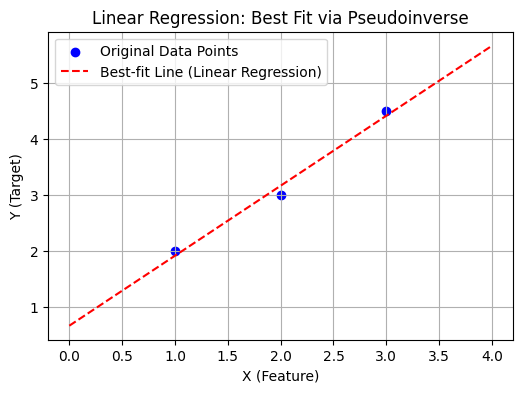

In [39]:
# Visualize the best-fit line
x_vals_for_plot = np.array([0, 4]) # Range for plotting the line
y_vals_for_plot = coefficients[0] * x_vals_for_plot + coefficients[1]

plt.figure(figsize=(6, 4))
plt.scatter(A[:, 0], b, color='blue', label='Original Data Points')
plt.plot(x_vals_for_plot, y_vals_for_plot, color='red', linestyle='--', label='Best-fit Line (Linear Regression)')
plt.title('Linear Regression: Best Fit via Pseudoinverse')
plt.xlabel('X (Feature)')
plt.ylabel('Y (Target)')
plt.grid(True)
plt.legend()
plt.show()

### Task 3.1: Linear regression via pseudoinverse

Consider a very simple dataset representing "hours studied" vs. "exam score":
- hours_studied = np.array([1, 2, 3, 4])
- exam_score = np.array([60, 70, 75, 85])

Formulate the A matrix and b vector for a linear regression model ***score = m * hours + c***. Then, use np.linalg.pinv() to find the best-fit **m** (slope) and **c** (intercept).

In [ ]:
# your code here
hours_studied = np.array([1, 2, 3, 4])
exam_score = np.array([60, 70, 75, 85])

print("Hours studied:", hours_studied )
print("Exam scores:", exam_score)

Hours studied: [1 2 3 4]
Exam scores: [60 70 75 85]


In [ ]:
#Build the equeations
A = np.column_stack([hours_studied, np.ones(len(hours_studied))])
b = exam_score

coefficients = np.linalg.pinv(A) @ b

m = coefficients[0]  # slope
c = coefficients[1]  # intercept
print(f"m = {m}, c = {c}")

[ 8.  52.5]
m = 7.999999999999993, c = 52.499999999999986


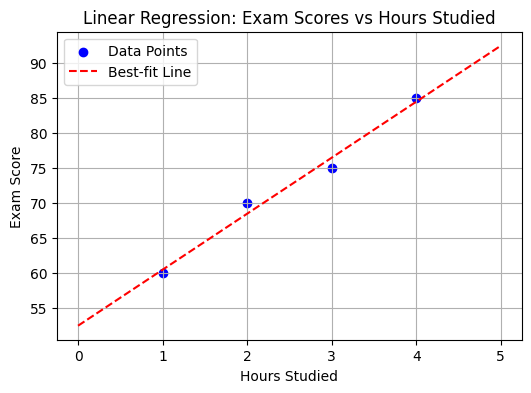

In [55]:
# Visualise
x_vals_for_plot = np.array([0, 5]) # Range for plotting the line
y_vals_for_plot = m * x_vals_for_plot + c

plt.figure(figsize=(6, 4))
plt.scatter(hours_studied, exam_score, color='blue', label='Data Points')
plt.plot(x_vals_for_plot, y_vals_for_plot, color='red', linestyle='--', label='Best-fit Line')
plt.title('Linear Regression: Exam Scores vs Hours Studied')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.grid(True)
plt.legend()
plt.show()

### OTJ Task 3.2: Multivariable linear regression`

For a dataset with multiple features (e.g., **[Age, Income]**) predicting a target **Rating**:
- features = np.array([[25, 40], [30, 50], [35, 45], [40, 60]])
- rating = np.array([7, 8, 7.5, 9])

Modify the A matrix construction to include an intercept term (a column of ones). Then, use np.linalg.pinv() to find the coefficients ***[m_age, m_income, c]*** for the model ***rating = m_age * Age + m_income * Income + c***.

In [57]:
# your code here

features = np.array([[25, 40], [30, 50], [35, 45], [40, 60]])
rating = np.array([7, 8, 7.5, 9])

A = np.column_stack([features, np.ones(len(features))])
b = rating

coefficients = np.linalg.pinv(A) @ b

print("Coefficients (weights and bias):", coefficients)

print(f"m_age    = {coefficients[0]:.4f}")
print(f"m_income = {coefficients[1]:.4f}")
print(f"c        = {coefficients[2]:.4f}")

Coefficients (weights and bias): [4.88498131e-15 1.00000000e-01 3.00000000e+00]
m_age    = 0.0000
m_income = 0.1000
c        = 3.0000


####  Pause and reflect

- The pseudoinverse gives the line that *minimises squared error*. Why squared? What would minimising absolute error instead give you?
- In Task 3.2, you added a column of ones to the feature matrix. What mathematical role does that column play, and what parameter does it correspond to in the model?

# 4. Matrix decomposition: eigenvalues and eigenvectors

## Why this matters

Imagine you have a dataset with 100 features. Many of those features are probably correlated (e.g., height and weight; age and years of experience). This creates redundancy: you're carrying a lot of dimensions that don't add much independent information.

**Principal Component Analysis (PCA)** is the standard technique for solving this. It finds the directions in which your data varies most, so you can keep just those directions and discard the rest, reducing 100 features to, say, 5, while retaining most of the useful information.

The mathematical engine behind PCA is eigenvalues and eigenvectors. But you don't need to master the algebra to use PCA effectively. The goal here is to build enough intuition to understand *what the numbers mean*.

## Building intuition: what is an eigenvector?

Think of a matrix as a machine that transforms space - it stretches, rotates, and shears vectors. When you multiply most vectors by a matrix, they change direction. But certain special vectors only get *scaled*, they keep pointing in the same direction.

These special vectors are **eigenvectors**. The amount they're scaled by is the **eigenvalue**.

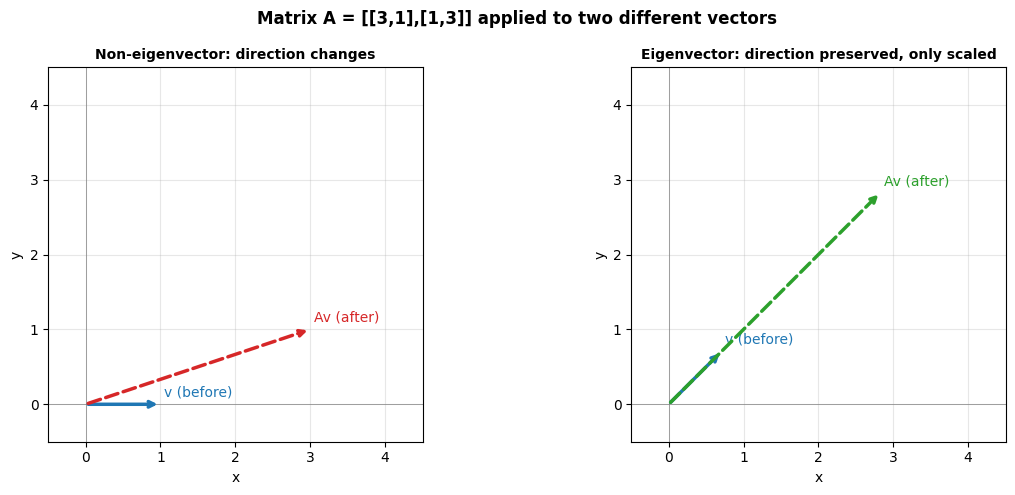

Non-eigenvector: v = [1 0]  →  Av = [3 1]  (direction changed)
Eigenvector:     v ≈ [0.707 0.707]  →  Av ≈ [2.828 2.828]  (scaled by λ=4, direction unchanged)


In [42]:
# Visualise the difference between regular vectors and eigenvectors
A = np.array([[3, 1],
              [1, 3]])

# Two test vectors: one is an eigenvector direction, one is not
v_regular = np.array([1, 0])       # not an eigenvector of A
v_eigen   = np.array([1, 1]) / np.sqrt(2)   # eigenvector of A (λ=4)

Av_regular = A @ v_regular
Av_eigen   = A @ v_eigen

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (label, v, Av, colour) in zip(axes, [
    ('Non-eigenvector: direction changes', v_regular, Av_regular, 'tab:red'),
    ('Eigenvector: direction preserved, only scaled', v_eigen, Av_eigen, 'tab:green'),
]):
    # Draw original vector
    ax.annotate('', xy=(v[0], v[1]), xytext=(0,0),
                arrowprops=dict(arrowstyle='->', color='tab:blue', lw=2.5))
    ax.text(v[0]+0.05, v[1]+0.1, 'v (before)', color='tab:blue', fontsize=10)
    # Draw transformed vector
    ax.annotate('', xy=(Av[0], Av[1]), xytext=(0,0),
                arrowprops=dict(arrowstyle='->', color=colour, lw=2.5, linestyle='dashed'))
    ax.text(Av[0]+0.05, Av[1]+0.1, 'Av (after)', color=colour, fontsize=10)
    
    ax.set_xlim(-0.5, 4.5); ax.set_ylim(-0.5, 4.5)
    ax.set_aspect('equal'); ax.grid(True, alpha=0.3)
    ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
    ax.set_title(label, fontsize=10, fontweight='bold')
    ax.set_xlabel('x'); ax.set_ylabel('y')

plt.suptitle('Matrix A = [[3,1],[1,3]] applied to two different vectors', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Non-eigenvector: v = {v_regular}  →  Av = {Av_regular}  (direction changed)")
print(f"Eigenvector:     v ≈ {v_eigen.round(3)}  →  Av ≈ {Av_eigen.round(3)}  (scaled by λ=4, direction unchanged)")

# Matrix decomposition for ML(Eigenvalues, Eigenvectors)

**Matrix decomposition** (or factorisation) is the process of breaking down a matrix into simpler component matrices. It reveals the fundamental properties of the original matrix and simplifies computations. It's like finding the "building blocks" of a matrix.

#### ML relevance

The matrix decomposition is the backbone of many advanced algorithms, particularly for dimensionality reduction, feature extraction, and understanding the underlying structure of data.

## Determinant
- A scalar value that can be computed from the elements of a square matrix.

#### ML relevance

A non-zero determinant indicates that a square matrix is invertible, which is necessary for unique solutions in Ax=b systems and for some transformations. A determinant of zero means the matrix is "singular" and its columns (or rows) are linearly dependent (meaning one column can be expressed as a linear combination of others, leading to redundancy).

## Eigenvalues and Eigenvectors

For a square matrix A, an **eigenvector (v)** is a non-zero vector that, when multiplied by A, only changes in magnitude (is scaled), not direction. The amount it's scaled by is its corresponding **eigenvalue (λ)**.

Expressed mathematically as: Av=λv

Imagine a transformation applied by matrix A. Eigenvectors are the "special directions" that remain unchanged (only stretched or shrunk) during this transformation. Eigenvalues tell you how much they are stretched/shrunk.

#### ML relevance
- **Principal Component Analysis (PCA)**: This is the most crucial application. PCA finds the principal components (new axes for your data) by calculating the eigenvectors of the data's covariance matrix.
- **Covariance Matrix**: Describes the variance within each feature and the covariance between pairs of features. Its eigenvectors represent directions of maximum variance in the data.
- **Eigenvalues in PCA**: The eigenvalues corresponding to these eigenvectors tell you the amount of variance captured along each principal component. Larger eigenvalues mean more variance.

### Deep dive: finding eigenvalues by hand (optional)

The section below shows the full algebraic derivation. This is useful background for understanding what NumPy is doing under the hood, but **you won't need to do this by hand in practice** - `np.linalg.eig()` handles it.

Work through it if you're comfortable with algebra; if not, focus on the NumPy section below and the conceptual interpretation that follows.

A solved example:

Find the eigenvalues (λ) and corresponding eigenvectors (v) for the matrix A:

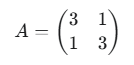

The defining equation is: **Av=λv**

We can rewrite this equation to solve for λ and v:

**Av−λv=0**

**Av−λIv=0** (where **I** is the identity matrix)
- For two matrices to be subtracted, they must have the exact same dimensions. A is an n×n matrix. You cannot subtract a scalar λ from an n×n matrix A.
- The Identity Matrix (I) is a special square matrix with ones on its main diagonal and zeros elsewhere. It has the unique property that when you multiply any vector or matrix by the identity matrix, it remains unchanged. For a vector v, Iv=v. Therefore, if we want to represent λv as a matrix-vector product, we can write it as (λI)v.

**(A−λI)v=0**

For a non-zero vector v to satisfy this equation, the matrix (A−λI) must be singular (non-invertible). This means its determinant must be zero.

**Step 1**: Form the characteristic equation to find Eigenvalues (λ).

We need to solve det(A−λI)=0.
First, let's form the matrix (A−λI):

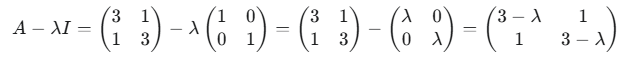

Now, calculate the determinant of this new matrix:

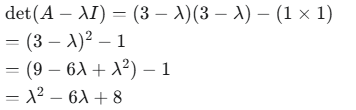

Set the determinant to zero to find the eigenvalues:

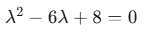

This is a quadratic equation. We can solve it by factoring:



So, the eigenvalues are:

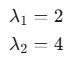

**Step 2**: Find the Eigenvectors (v) for Each Eigenvalue

For each eigenvalue, we substitute it back into the equation (A−λI)v=0 and solve for

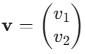

For 



Substitute λ=2 into (A−λI)v=0:

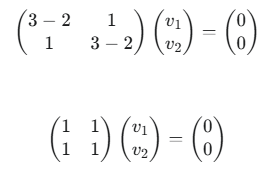

This gives us a system of two identical equations:

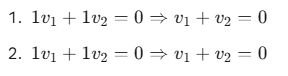

From 



we get



Since eigenvectors are defined up to a scalar multiple, we can choose a simple non-zero value for $v_2$.

Let $v_2=1$, then $v_1=−1$.

So, an eigenvector for $λ_1=2$ is  

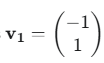

The np.linalg.eig() function outputs normalised vectors. So, to normalise $v_1$:

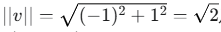

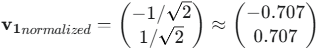

For $λ_2=4$:

Substitute λ=4 into (A−λI)v=0:

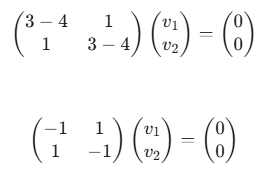

This gives us a system of two identical equations:

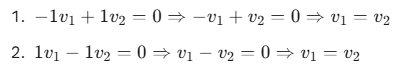

From $v_1=v_2$, we can choose a simple non-zero value for $v_2$.

Let $v_2=1$, then $v_1=1$.

So, an eigenvector for $λ_2=4$ is

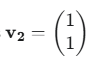

Optional: Normalisation of the eigenvector(to see the same results as in NumPy):

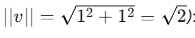

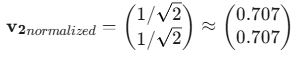

### Finding eigenvalues with NumPy

In practice, you will always use `np.linalg.eig()`. Let's verify the hand-calculated results above and build intuition about what the output means.

In [43]:
# Define a small, symmetric matrix (e.g., representing a simplified covariance matrix)
cov_matrix_example = np.array([[3, 1],
                               [1, 3]])
print(cov_matrix_example)

# Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix_example)

print(eigenvalues)
print(eigenvectors)

# Each column of 'eigenvectors' corresponds to an eigenvalue in 'eigenvalues'
# The first column `eigenvectors[:, 0]` is the eigenvector for `eigenvalues[0]`
# The second column `eigenvectors[:, 1]` is the eigenvector for `eigenvalues[1]`

[[3 1]
 [1 3]]
[4. 2.]
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


- The larger the eigenvalue, the more "information" or "spread" (variance) is captured along its corresponding eigenvector's direction.
- Here, $λ_1=4$ is greater than $λ_2=2$. This tells us that the direction defined by $v_1$ is twice as important (captures twice as much variance) as the direction defined by $v_2$.
- If this matrix represented the covariance of a dataset, it means the data points are much more spread out along the direction of $v_1$ than along $v_2$.

If this matrix A were the covariance matrix of a 2-dimensional dataset (where the features had means of zero, or the data was centered), then:
- The principal components of that dataset would be along the directions of $v_1$ and $v_2$.
- The first principal component would be in the direction of
  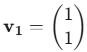
  because its eigenvalue ($λ_1=4$) is the largest, indicating it captures the most variance.
- The second principal component would be in the direction of
  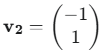
  because its eigenvalue ($λ_2=2$) is the second largest.
- If you wanted to reduce the dimensionality of this 2D data to 1D while retaining as much information (variance) as possible, you would project the data onto the first principal component (the direction of $v_1$). You would effectively discard the information along $v_2$, as it accounts for less of the overall spread.

## PCA: from eigenvalues to dimensionality reduction

### Step 1: Build the intuition with a simple example

Before using sklearn, let's walk through PCA manually on a small 2D dataset so you can see *exactly* what happens at each step. This is the same process sklearn does internally.

Covariance matrix:
[[87.17 74.23]
 [74.23 82.09]]

Eigenvalue 1 (PC1): 158.91  →  captures most variance
Eigenvalue 2 (PC2): 10.36  →  captures less variance

PC1 direction: [0.719 0.695]
PC2 direction: [-0.695  0.719]

Variance explained by PC1: 93.9%
Variance explained by PC2: 6.1%

If we kept only PC1, we'd retain 93.9% of the information
and reduce the data from 2 features to 1 — with relatively little loss.


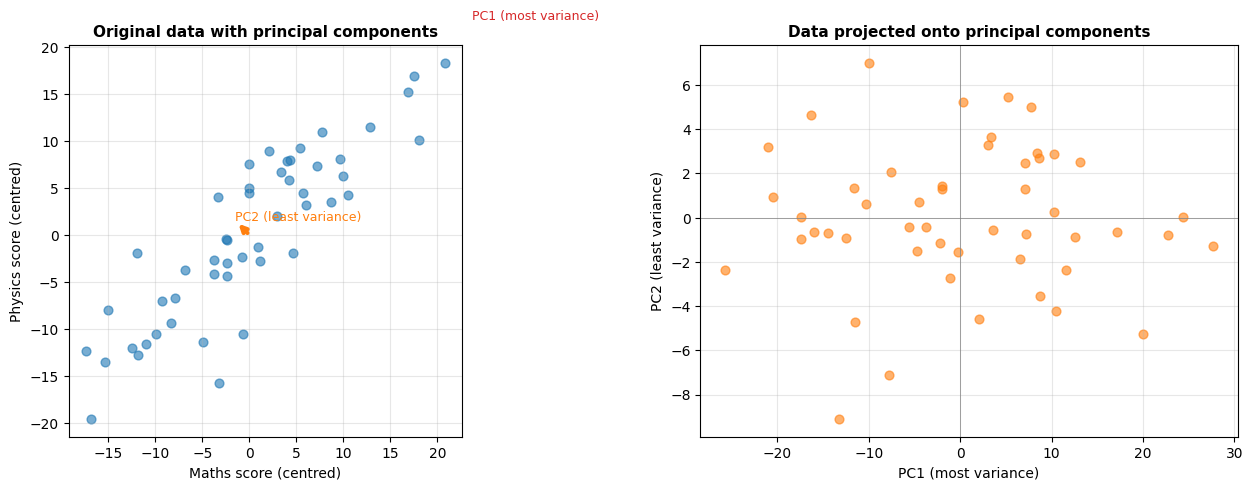

In [44]:
# PCA from scratch on a simple 2D dataset
# Data: student exam scores in two subjects (correlated)
np.random.seed(42)
scores_maths  = np.random.normal(60, 10, 50)
scores_physics = scores_maths * 0.8 + np.random.normal(0, 5, 50)

X_2d = np.column_stack([scores_maths, scores_physics])

# Step 1: Centre the data (subtract the mean)
X_centred = X_2d - X_2d.mean(axis=0)

# Step 2: Compute the covariance matrix
cov_matrix = np.cov(X_centred.T)
print("Covariance matrix:")
print(cov_matrix.round(2))
print()

# Step 3: Find eigenvalues and eigenvectors of the covariance matrix
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)

# Sort by eigenvalue (largest first)
idx = np.argsort(eigenvalues)[::-1]
eigenvalues  = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]

print(f"Eigenvalue 1 (PC1): {eigenvalues[0]:.2f}  →  captures most variance")
print(f"Eigenvalue 2 (PC2): {eigenvalues[1]:.2f}  →  captures less variance")
print()
print(f"PC1 direction: {eigenvectors[:, 0].round(3)}")
print(f"PC2 direction: {eigenvectors[:, 1].round(3)}")

# Step 4: Project data onto principal components
X_pca = X_centred @ eigenvectors

# Plot
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X_centred[:, 0], X_centred[:, 1], alpha=0.6, color='tab:blue', s=40)
scale = 30
for i, (ev, lbl) in enumerate(zip(eigenvectors.T, ['PC1 (most variance)', 'PC2 (least variance)'])):
    axes[0].annotate('', xy=(ev[0]*scale*eigenvalues[i]/eigenvalues[0], ev[1]*scale*eigenvalues[i]/eigenvalues[0]),
                     xytext=(0, 0),
                     arrowprops=dict(arrowstyle='->', color=['tab:red', 'tab:orange'][i], lw=3))
    axes[0].text(ev[0]*scale*eigenvalues[i]/eigenvalues[0]*1.1,
                 ev[1]*scale*eigenvalues[i]/eigenvalues[0]*1.1, lbl, fontsize=9,
                 color=['tab:red', 'tab:orange'][i])
axes[0].set_title('Original data with principal components', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Maths score (centred)'); axes[0].set_ylabel('Physics score (centred)')
axes[0].set_aspect('equal'); axes[0].grid(True, alpha=0.3)

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6, color='tab:orange', s=40)
axes[1].set_title('Data projected onto principal components', fontsize=11, fontweight='bold')
axes[1].set_xlabel('PC1 (most variance)'); axes[1].set_ylabel('PC2 (least variance)')
axes[1].axhline(0, color='grey', lw=0.5); axes[1].axvline(0, color='grey', lw=0.5)
axes[1].grid(True, alpha=0.3)

total_var = eigenvalues.sum()
print(f"\nVariance explained by PC1: {eigenvalues[0]/total_var*100:.1f}%")
print(f"Variance explained by PC2: {eigenvalues[1]/total_var*100:.1f}%")
print(f"\nIf we kept only PC1, we'd retain {eigenvalues[0]/total_var*100:.1f}% of the information")
print(f"and reduce the data from 2 features to 1 — with relatively little loss.")

plt.tight_layout()
plt.show()

### Step 2: Using sklearn for PCA on larger data

Now that you've seen PCA from scratch, sklearn's implementation does the same thing, just faster and more robustly for high-dimensional data.

In [45]:

# Sample Data: 4 samples, 3 features
# [Age, Income, SpendingScore]
data_for_pca = np.array([[20, 50000, 100],
                         [25, 60000, 120],
                         [30, 70000, 150],
                         [40, 80000, 180]])

In [46]:
# PCA from scikit-learn
# Initialise PCA - let's reduce to 2 components
pca = PCA(n_components=2)

In [47]:
# Fit PCA to the data and transform it
transformed_data = pca.fit_transform(data_for_pca)

In [48]:
print(transformed_data)

[[-1.50000491e+04  3.15953632e+00]
 [-5.00003041e+03 -3.91656025e+00]
 [ 5.00001528e+03 -1.64547915e+00]
 [ 1.50000642e+04  2.40250308e+00]]


In [49]:
# Explained Variance Ratio: How much variance each component captures
print(pca.explained_variance_ratio_)
print(pca.explained_variance_ratio_.sum())

# The first value in pca.explained_variance_ratio_ represents the percentage of variance captured by the first component.

[9.99999925e-01 6.76029470e-08]
0.9999999926040449


In [50]:
# The Principal Components themselves (these are the eigenvectors in the original feature space)
print(pca.components_)

[[ 6.49997557e-04  9.99996144e-01  2.69998976e-03]
 [ 3.55380227e-01 -2.75473531e-03  9.34717768e-01]]


### Task 4.1: Apply PCA to a larger dataset.

Load a more substantial (but still small enough for quick processing) dataset, such as the Iris dataset from sklearn.datasets.
1. Load the data: ***from sklearn.datasets import load_iris; iris = load_iris(); X = iris.data***.
2. Apply PCA(n_components=2) to X.
3. Print the transformed_data and explained_variance_ratio_.

#### Pause and reflect - Task 4.1 follow-up

After running PCA on the Iris dataset, answer the following:

1. The `explained_variance_ratio_` gives the proportion of variance captured by each component. How much total variance do 2 components capture? Is that enough to justify reducing from 4 features to 2?
2. If you ran `PCA(n_components=4)`, what would `explained_variance_ratio_.sum()` equal, and why?
3. In a real ML pipeline, where in the workflow would you apply PCA - before or after splitting into train/test sets? Why does this matter?

Original shape: (150, 4)
Reduced shape: (150, 2)
Variance explained: [0.92461872 0.05306648]
Total variance retained: 0.978


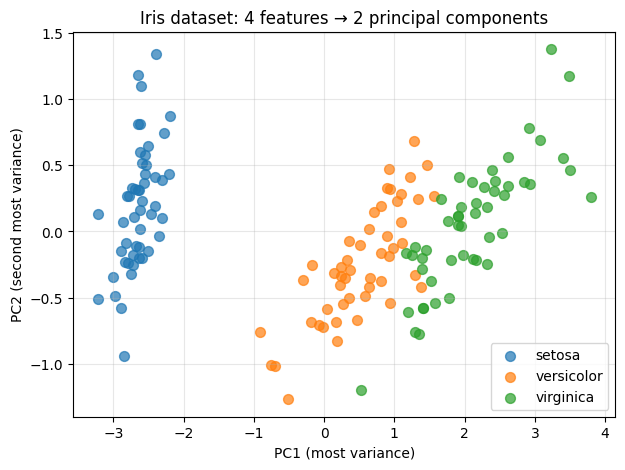

In [59]:
from sklearn.datasets import load_iris
iris = load_iris()
X = iris.data

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X)

print("Original shape:", X.shape)
print("Reduced shape:", X_reduced.shape)
print("Variance explained:", pca.explained_variance_ratio_)
print("Total variance retained:", pca.explained_variance_ratio_.sum().round(3))

# Visualise - colour by species so we can see if PCA preserves class separation
colours = ['tab:blue', 'tab:orange', 'tab:green']
species = iris.target_names

plt.figure(figsize=(7, 5))
for i, species_name in enumerate(species):
    mask = iris.target == i
    plt.scatter(X_reduced[mask, 0], X_reduced[mask, 1], 
                label=species_name, color=colours[i], alpha=0.7, s=50)

plt.xlabel('PC1 (most variance)')
plt.ylabel('PC2 (second most variance)')
plt.title('Iris dataset: 4 features → 2 principal components')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()